# Start Here

In [1]:
import pandas as pd
import re
import numpy as np
import time
import requests

In [2]:
western_teams = ['OKC', 'DEN', 'LAL', 'HOU', 'SAS', 'PHO', 'MIN', 'GSW', 'POR', 'MEM', 'UTA', 'LAC', 'SAC', 'DAL', 'NOP']
guard = ['SG', 'PG']


def clean_data(df):
  df = df.drop(df.index[-1])
  df = df.fillna(0)
  df = df[(df['Team'] != '2TM') & (df['Team'] != '3TM') & (df['Team'] != '4TM')]
  df['West'] = df['Team'].isin(western_teams).astype(int)
  df['Guard'] = df['Pos'].isin(guard).astype(int)
  df = df.reset_index(drop=True)
  return df

In [5]:
df_2026 = pd.read_csv("2025-2026.csv")
df_2024 = pd.read_csv("2023-2024.csv")
df_2023 = pd.read_csv("2022-2023.csv")
df_2022 = pd.read_csv("2021-2022.csv")
df_2021 = pd.read_csv("2020-2021.csv")
df_2020 = pd.read_csv("2019-2020.csv")

In [6]:
df_2026 = clean_data(df_2026)
df_2024 = clean_data(df_2024)
df_2023 = clean_data(df_2023)
df_2022 = clean_data(df_2022)
df_2021 = clean_data(df_2021)
df_2020 = clean_data(df_2020)

In [7]:
all_star_list_2024 = ['Giannis Antetokounmpo', 'Bam Adebayo', 'Tyrese Haliburton', 'Damian Lillard', 'Jayson Tatum', 'Paolo Banchero',
                 'Jaylen Brown', 'Jalen Brunson', 'Tyrese Maxey', 'Donovan Mitchell', 'Julius Randle', 'Joel Embiid',
                 'LeBron James', 'Luka Dončić', 'Kevin Durant', 'Shai Gilgeous-Alexander', 'Nikola Jokić', 'Devin Booker', 'Stephen Curry', 'Anthony Davis',
                 'Anthony Edwards', 'Paul George', 'Kawhi Leonard', 'Karl-Anthony Towns']

all_star_list_2023 = ['Giannis Antetokounmpo', 'Lauri Markkanen', 'Donovan Mitchell', 'Ja Morant', 'Jayson Tatum', 'Bam Adebayo',
                 'Shai Gilgeous-Alexander', 'DeMar DeRozan', 'Jrue Holiday', 'Damian Lillard', 'Domantas Sabonis', 'Kevin Durant',
                 'LeBron James', 'Luka Dončić', 'Joel Embiid', 'Kyrie Irving', 'Nikola Jokić', 'Jaylen Brown', 'Stephen Curry', 'Paul George',
                 'Tyrese Haliburton', 'Jaren Jackson Jr.', 'Julius Randle', 'Zion Williamson']

all_star_list_2022 = ['Kevin Durant', 'Joel Embiid', 'Ja Morant', 'Jayson Tatum', 'Andrew Wiggins', 'Trae Young',
                 'Devin Booker', 'Rudy Gobert', 'Zach LaVine', 'Khris Middleton', 'Karl-Anthony Towns', 'Draymond Green',
                 'LeBron James', 'Luka Dončić', 'Giannis Antetokounmpo', 'Stephen Curry', 'Nikola Jokić', 'DeMar DeRozan', 'Jimmy Butler', 'Darius Garland',
                 'James Harden', 'Donovan Mitchell', 'Chris Paul', 'Fred VanVleet']

all_star_list_2021 = ['Giannis Antetokounmpo', 'Stephen Curry', 'Luka Dončić', 'LeBron James', 'Nikola Jokić', 'Jaylen Brown',
                 'Paul George', 'Rudy Gobert', 'Damian Lillard', 'Chris Paul', 'Ben Simmons',
                 'Bradley Beal', 'Kyrie Irving', 'Kawhi Leonard', 'Jayson Tatum', 'Zion Williamson', 'James Harden', 'Zach LaVine', 'Donovan Mitchell',
                 'Julius Randle', 'Nikola Vučević', 'Kevin Durant', 'Anthony Davis', 'Joel Embiid']

all_star_list_2020 = ['Anthony Davis', 'Kawhi Leonard', 'Luka Dončić', 'Damian Lillard', 'James Harden', 'Ben Simmons',
                 'Nikola Jokić', 'Jayson Tatum', 'Chris Paul', 'Russell Westbrook', 'Domantas Sabonis', 'LeBron James',
                 'Giannis Antetokounmpo', 'Joel Embiid', 'Pascal Siakam', 'Kemba Walker', 'Trae Young', 'Khris Middleton', 'Bam Adebayo', 'Rudy Gobert',
                 'Jimmy Butler', 'Kyle Lowry', 'Brandon Ingram', 'Donovan Mitchell']


In [8]:
df_2024['All Star'] = df_2024['Player'].isin(all_star_list_2024).astype(int)
df_2023['All Star'] = df_2023['Player'].isin(all_star_list_2023).astype(int)
df_2022['All Star'] = df_2022['Player'].isin(all_star_list_2022).astype(int)
df_2021['All Star'] = df_2021['Player'].isin(all_star_list_2021).astype(int)
df_2020['All Star'] = df_2020['Player'].isin(all_star_list_2020).astype(int)

In [9]:
def add_year(df, year):
  df['Year'] = year
  return df

df_2026 = add_year(df_2026, 2026)
df_2024 = add_year(df_2024, 2024)
df_2023 = add_year(df_2023, 2023)
df_2022 = add_year(df_2022, 2022)
df_2021 = add_year(df_2021, 2021)
df_2020 = add_year(df_2020, 2020)

In [10]:
df_2020

,Rk,Player,Age,Team,Pos,G,GS,MP,FG,FGA,...,STL,BLK,TOV,PF,PTS,Awards,West,Guard,All Star,Year
0,1.0,James Harden,30.0,HOU,SG,68.0,68.0,36.5,9.9,22.3,...,1.8,0.9,4.5,3.3,34.3,"MVP-3,AS,NBA1",1,1,1,2020
1,2.0,Bradley Beal,26.0,WAS,SG,57.0,57.0,36.0,10.4,22.9,...,1.2,0.4,3.4,2.2,30.5,0,0,1,0,2020
2,3.0,Damian Lillard,29.0,POR,PG,66.0,66.0,37.5,9.5,20.4,...,1.1,0.3,2.9,1.7,30.0,"MVP-8,AS,NBA2",1,1,1,2020
3,4.0,Trae Young,21.0,ATL,PG,60.0,60.0,35.3,9.1,20.8,...,1.1,0.1,4.8,1.7,29.6,AS,0,1,1,2020
4,5.0,Giannis Antetokounmpo,25.0,MIL,PF,63.0,63.0,30.4,10.9,19.7,...,1.0,1.0,3.7,3.1,29.5,"MVP-1,DPOY-1,AS,NBA1,DEF1",0,0,1,2020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586,525.0,Marques Bolden,21.0,CLE,C,1.0,0.0,3.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0,0,0,0,2020
587,526.0,William Howard,26.0,HOU,PF,2.0,0.0,6.5,0.0,2.0,...,0.0,0.0,0.5,0.5,0.0,0,1,0,0,2020
588,527.0,Stanton Kidd,27.0,UTA,SG,4.0,0.0,3.8,0.0,0.8,...,0.0,0.0,0.5,0.8,0.0,0,1,1,0,2020
589,528.0,J.P. Macura,24.0,CLE,SG,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2020


In [11]:
df_combined = pd.concat([df_2023, df_2022, df_2021, df_2020])

# Get X and y

In [12]:
# X_train = df_combined[['Age', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']]
X_train = df_combined[['Age', 'G', 'GS', '3P', '3P%', '2P%', 'eFG%', 'FT%', 'ORB', 'DRB', 'AST', 'STL', 'BLK', 'PF', 'PTS']]
y_train = df_combined['All Star']
# X_test = df_2024[['Age', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']]
X_test = df_2024[['Age', 'G', 'GS', '3P', '3P%', '2P%', 'eFG%', 'FT%', 'ORB', 'DRB', 'AST', 'STL', 'BLK', 'PF', 'PTS']]
y_test = df_2024['All Star']

X_2026 = df_2026[['Age', 'G', 'GS', '3P', '3P%', '2P%', 'eFG%', 'FT%', 'ORB', 'DRB', 'AST', 'STL', 'BLK', 'PF', 'PTS']]

In [13]:
display(X_train)
display(y_train)
display(X_test)
display(y_test)

,Age,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,28.0,66.0,66.0,34.6,11.0,20.1,0.548,1.0,3.0,0.330,...,0.857,1.7,8.4,10.2,4.2,1.0,1.7,3.4,3.1,33.1
1,23.0,66.0,66.0,36.2,10.9,22.0,0.496,2.8,8.2,0.342,...,0.742,0.8,7.8,8.6,8.0,1.4,0.5,3.6,2.5,32.4
2,32.0,58.0,58.0,36.3,9.6,20.7,0.463,4.2,11.3,0.371,...,0.914,0.8,4.0,4.8,7.3,0.9,0.3,3.3,1.9,32.2
3,24.0,68.0,68.0,35.5,10.4,20.3,0.510,0.9,2.5,0.345,...,0.905,0.9,4.0,4.8,5.5,1.6,1.0,2.8,2.8,31.4
4,28.0,63.0,63.0,32.1,11.2,20.3,0.553,0.7,2.7,0.275,...,0.645,2.2,9.6,11.8,5.7,0.8,0.8,3.9,3.1,31.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
586,21.0,1.0,0.0,3.0,0.0,0.0,0.000,0.0,0.0,0.000,...,0.000,0.0,2.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0
587,26.0,2.0,0.0,6.5,0.0,2.0,0.000,0.0,2.0,0.000,...,0.000,0.0,1.0,1.0,0.5,0.0,0.0,0.5,0.5,0.0
588,27.0,4.0,0.0,3.8,0.0,0.8,0.000,0.0,0.3,0.000,...,0.000,0.0,0.8,0.8,0.3,0.0,0.0,0.5,0.8,0.0
589,24.0,1.0,0.0,1.0,0.0,0.0,0.000,0.0,0.0,0.000,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,All Star
0,1
1,1
2,1
3,1
4,1
...,...
586,0
587,0
588,0
589,0


,Age,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,29.0,39.0,39.0,33.6,11.5,21.8,0.529,1.4,3.6,0.388,...,0.883,2.4,8.6,11.0,5.6,1.2,1.7,3.8,2.9,34.7
1,24.0,70.0,70.0,37.5,11.5,23.6,0.487,4.1,10.6,0.382,...,0.786,0.8,8.4,9.2,9.8,1.4,0.5,4.0,2.1,33.9
2,29.0,73.0,73.0,35.2,11.5,18.8,0.611,0.5,1.7,0.274,...,0.657,2.7,8.8,11.5,6.5,1.2,1.1,3.4,2.9,30.4
3,25.0,75.0,75.0,34.0,10.6,19.8,0.535,1.3,3.6,0.353,...,0.874,0.9,4.7,5.5,6.2,2.0,0.9,2.2,2.5,30.1
4,27.0,77.0,77.0,35.4,10.3,21.4,0.479,2.7,6.8,0.401,...,0.847,0.6,3.1,3.6,6.7,0.9,0.2,2.4,1.9,28.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652,36.0,2.0,0.0,9.0,0.0,1.0,0.000,0.0,0.5,0.000,...,0.000,0.0,1.0,1.0,0.5,0.5,0.0,0.0,0.5,0.0
653,23.0,1.0,0.0,4.0,0.0,0.0,0.000,0.0,0.0,0.000,...,0.000,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,0.0
654,28.0,2.0,0.0,0.5,0.0,0.0,0.000,0.0,0.0,0.000,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
655,25.0,2.0,0.0,1.0,0.0,0.5,0.000,0.0,0.0,0.000,...,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


,All Star
0,1
1,1
2,1
3,1
4,1
...,...
652,0
653,0
654,0
655,0


In [14]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neural_network import MLPClassifier

# 1) Logistic Regression
log_reg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=2000))
])

# # 2) Random Forest
# rf_model = RandomForestClassifier(
#     n_estimators=500,
#     max_depth=None,
#     min_samples_split=2,
#     random_state=42,
#     n_jobs=-1
# )


# # 3) Neural Network (MLP)
# nn_model = Pipeline([
#     ("scaler", StandardScaler()),
#     ("clf", MLPClassifier(
#         hidden_layer_sizes=(64, 32),
#         activation="relu",
#         max_iter=500,
#         random_state=42
#     ))
# ])




# log_reg_model = Pipeline([
#     ("scaler", StandardScaler()),
#     ("clf", LogisticRegression(max_iter=2000, random_state=42, solver='liblinear', C=0.1))
# ])

rf_model = RandomForestClassifier(
    n_estimators=500,
    max_depth=5,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

nn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=500,
        alpha=0.01,
        random_state=42
    ))
])

# Cross-validation

In [ ]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
import numpy as np

# 5-Fold stratified Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Predict probabilities for each model
proba_lr_cv_strat = cross_val_predict(log_reg_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
proba_rf_cv_strat = cross_val_predict(rf_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
proba_nn_cv_strat = cross_val_predict(nn_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]

y_train_actual = y_train

# Ensemble Stratified CV Probabilities
proba_ensemble_cv_strat = (proba_lr_cv_strat + proba_rf_cv_strat + proba_nn_cv_strat) / 3

# AUC
auc_lr_strat = roc_auc_score(y_train_actual, proba_lr_cv_strat)
auc_rf_strat = roc_auc_score(y_train_actual, proba_rf_cv_strat)
auc_nn_strat = roc_auc_score(y_train_actual, proba_nn_cv_strat)
auc_ensemble_strat = roc_auc_score(y_train_actual, proba_ensemble_cv_strat)

print(f"Logistic Regression CV AUC: {auc_lr_strat:.4f}")
print(f"Random Forest CV AUC: {auc_rf_strat:.4f}")
print(f"Neural Network CV AUC: {auc_nn_strat:.4f}")
print(f"Ensemble CV AUC: {auc_ensemble_strat:.4f}")


# Convert probabilities to binary predictions using a 0.5 threshold
y_pred_ensemble_strat = (proba_ensemble_cv_strat >= 0.5).astype(int)

# Accuracy
accuracy_strat = accuracy_score(y_train_actual, y_pred_ensemble_strat)
print(f"Ensemble Stratified CV Accuracy: {accuracy_strat:.4f}")

# Classification Report
print("Ensemble Stratified CV Classification Report:")
print(classification_report(y_train_actual, y_pred_ensemble_strat, target_names=['Not All-Star (0)', 'All-Star (1)'], zero_division=0))

Logistic Regression CV AUC: 0.9888
Random Forest CV AUC: 0.9889
Neural Network CV AUC: 0.9815
Ensemble CV AUC: 0.9893
Ensemble Stratified CV Accuracy: 0.9760
Ensemble Stratified CV Classification Report:
                  precision    recall  f1-score   support

Not All-Star (0)       0.98      0.99      0.99      2440
    All-Star (1)       0.74      0.60      0.67       101

        accuracy                           0.98      2541
       macro avg       0.86      0.80      0.83      2541
    weighted avg       0.97      0.98      0.97      2541



# Training Accuracy

In [15]:
log_reg_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
nn_model.fit(X_train, y_train)
proba_lr = log_reg_model.predict_proba(X_train)[:, 1]
proba_rf = rf_model.predict_proba(X_train)[:, 1]
proba_nn = nn_model.predict_proba(X_train)[:, 1]

df_combined["p_log_reg"] = proba_lr
df_combined["p_random_forest"] = proba_rf
df_combined["p_neural_net"] = proba_nn
df_combined["p_ensemble"] = df_combined[["p_log_reg", "p_random_forest", "p_neural_net"]].mean(axis=1)


from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
import numpy as np

# y_train_actual = df_combined['All Star']
# p_ensemble_train = df_combined['p_ensemble']


p_lr_train = df_combined['p_log_reg']
p_rf_train = df_combined['p_random_forest']
p_nn_train = df_combined['p_neural_net']

# AUC
auc_lr = roc_auc_score(df_combined['All Star'], p_lr_train)
auc_rf = roc_auc_score(df_combined['All Star'], p_rf_train)
auc_nn = roc_auc_score(df_combined['All Star'], p_nn_train)
auc_ensemble = roc_auc_score(df_combined['All Star'], df_combined['p_ensemble'])

print(f"Logistic Regression AUC: {auc_lr:.4f}")
print(f"Random Forest AUC: {auc_rf:.4f}")
print(f"Neural Network AUC: {auc_nn:.4f}")
print(f"Ensemble AUC: {auc_ensemble:.4f}")

df_combined_sorted = df_combined.sort_values(
    by='p_ensemble',
    ascending=False
)

# Set all prediction to 0 first
df_combined_sorted['Predicted All Star'] = 0

pred_all_star_index = df_combined_sorted.columns.get_loc('Predicted All Star')
df_combined_sorted = df_combined_sorted.reset_index(drop=True)

# Set the topk players based on p_ensemble values to 1
df_combined_sorted.iloc[0:101, pred_all_star_index] = 1

y_pred_ensemble = df_combined_sorted['Predicted All Star']
y_train_actual = df_combined_sorted['All Star']

# Accuracy
accuracy = accuracy_score(y_train_actual, y_pred_ensemble)
print(f"Ensemble Accuracy: {accuracy:.4f}")

# Classification Report
print(classification_report(y_train_actual, y_pred_ensemble, target_names=['Not All-Star (0)', 'All-Star (1)'], zero_division=0))

print("Top 35 Predicted All-Stars for 2020-2023:")
print(df_combined_sorted[['Player', 'West', 'Guard', 'p_log_reg', 'p_random_forest', 'p_neural_net', 'p_ensemble', 'All Star']].head(35).to_markdown(index=False))

# Save Prediction Results as csv file
df_combined_sorted_filtered = df_combined_sorted[['Player', 'West', 'Guard', 'Year', 'p_ensemble', 'All Star']]
df_combined_sorted_filtered.to_csv("2020_to_2023_All_Star_Predictions.csv", index=False)

Logistic Regression AUC: 0.9919
Random Forest AUC: 1.0000
Neural Network AUC: 1.0000
Ensemble AUC: 1.0000
Ensemble Accuracy: 0.9992
                  precision    recall  f1-score   support

Not All-Star (0)       1.00      1.00      1.00      2440
    All-Star (1)       0.99      0.99      0.99       101

        accuracy                           1.00      2541
       macro avg       0.99      0.99      0.99      2541
    weighted avg       1.00      1.00      1.00      2541

Top 35 Predicted All-Stars for 2020-2023:
| Player                  |   West |   Guard |   p_log_reg |   p_random_forest |   p_neural_net |   p_ensemble |   All Star |
|:------------------------|-------:|--------:|------------:|------------------:|---------------:|-------------:|-----------:|
| Joel Embiid             |      0 |       0 |    0.997745 |             0.986 |       0.999905 |     0.99455  |          1 |
| Kevin Durant            |      0 |       0 |    0.989066 |             0.992 |       0.999973 |

#Test 2024 Accuracy

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
import pandas as pd
import numpy as np

# log_reg_features = ['Age', 'G', '3P%', 'eFG%', 'FT%', 'ORB', 'STL', 'BLK', 'PF', 'PTS']
# rf_features = ['Age', 'G', 'GS', '3P', '3P%', 'eFG%', 'FT%', 'ORB', 'DRB', 'AST', 'STL', 'BLK', 'PF', 'PTS']
# nn_features

proba_lr_test = log_reg_model.predict_proba(X_test)[:, 1]
proba_rf_test = rf_model.predict_proba(X_test)[:, 1]
proba_nn_test = nn_model.predict_proba(X_test)[:, 1]

# Add probabilities to the 2024 DataFrame
df_2024["p_log_reg"] = proba_lr_test
df_2024["p_random_forest"] = proba_rf_test
df_2024["p_neural_net"] = proba_nn_test

df_2024["p_ensemble"] = df_2024[["p_log_reg", "p_random_forest", "p_neural_net"]].mean(axis=1)


# AUC
ensemble_auc = roc_auc_score(y_test, df_2024['p_ensemble'])
print(f"Ensemble Area Under the ROC Curve (AUC): {ensemble_auc:.4f}")

df_2024_sorted = df_2024.sort_values(
    by='p_ensemble',
    ascending=False
)

# Set all prediction to 0 first
df_2024_sorted['Predicted All Star'] = 0

pred_all_star_index = df_combined_sorted.columns.get_loc('Predicted All Star')
df_2024_sorted = df_2024_sorted.reset_index(drop=True)

# Set the topk players based on p_ensemble values to 1
df_2024_sorted.iloc[0:24, pred_all_star_index] = 1

y_pred_ensemble = df_2024_sorted['Predicted All Star']
y_test_actual = df_2024_sorted['All Star']

# Accuracy
accuracy = accuracy_score(y_test_actual, y_pred_ensemble)
print(f"Ensemble Accuracy: {accuracy:.4f}")

# Classification Report
print("Ensemble Classification Report:")
print(classification_report(y_test_actual, y_pred_ensemble, target_names=['Not All-Star (0)', 'All-Star (1)'], zero_division=0))


print("Top 35 Predicted All-Stars for 2024:")
# Display the results
print(df_2024_sorted[['Player', 'West', 'Guard', 'p_log_reg', 'p_random_forest', 'p_neural_net', 'p_ensemble', 'All Star']].head(35).to_markdown(index=False))

# Save the full 2024 prediction results to a CSV for the user
df_2024_sorted_filtered = df_2024_sorted[['Player', 'West', 'Guard', 'Year', 'p_ensemble', 'All Star']]
df_2024_sorted_filtered.to_csv("2024_All_Star_Predictions.csv", index=False)

Ensemble Area Under the ROC Curve (AUC): 0.9918
Ensemble Accuracy: 0.9756
Ensemble Classification Report:
                  precision    recall  f1-score   support

Not All-Star (0)       0.99      0.99      0.99       633
    All-Star (1)       0.67      0.67      0.67        24

        accuracy                           0.98       657
       macro avg       0.83      0.83      0.83       657
    weighted avg       0.98      0.98      0.98       657

Top 35 Predicted All-Stars for 2024:
| Player                  |   West |   Guard |   p_log_reg |   p_random_forest |   p_neural_net |   p_ensemble |   All Star |
|:------------------------|-------:|--------:|------------:|------------------:|---------------:|-------------:|-----------:|
| Luka Dončić             |      1 |       1 |    0.999343 |             0.926 |    0.999999    |     0.975114 |          1 |
| Nikola Jokić            |      1 |       0 |    0.996299 |             0.874 |    0.99987     |     0.956723 |          1 |
| 

# 2025-2026 Prediction

In [ ]:
proba_lr_test = log_reg_model.predict_proba(X_2026)[:, 1]
proba_rf_test = rf_model.predict_proba(X_2026)[:, 1]
proba_nn_test = nn_model.predict_proba(X_2026)[:, 1]

df_2026["p_log_reg"] = proba_lr_test
df_2026["p_random_forest"] = proba_rf_test
df_2026["p_neural_net"] = proba_nn_test
df_2026["p_ensemble"] = df_2026[["p_log_reg", "p_random_forest", "p_neural_net"]].mean(axis=1)

df_2026_sorted = df_2026.sort_values(
    by='p_ensemble',
    ascending=False
)

print("\nTop 24 Predicted All-Stars for 2026:")
# Display the results
print(df_2026_sorted[['Player', 'West', 'Guard', 'p_log_reg', 'p_random_forest', 'p_neural_net', 'p_ensemble']].head(35).to_markdown(index=False))

# Save the full 2026 prediction results to a CSV for the user
df_2026_sorted_filtered = df_2026_sorted[['Player', 'West', 'Guard', 'Year', 'p_ensemble']]
df_2026_sorted_filtered.to_csv("2026_All_Star_Predictions.csv", index=False)


Top 24 Predicted All-Stars for 2026:
| Player                  |   West |   Guard |   p_log_reg |   p_random_forest |   p_neural_net |   p_ensemble |
|:------------------------|-------:|--------:|------------:|------------------:|---------------:|-------------:|
| Nikola Jokić            |      1 |       0 |   0.997309  |         0.635727  |    0.999924    |    0.877654  |
| Luka Dončić             |      1 |       1 |   0.996875  |         0.608509  |    0.998375    |    0.86792   |
| Victor Wembanyama       |      1 |       0 |   0.952243  |         0.549596  |    0.999632    |    0.833824  |
| James Harden            |      1 |       1 |   0.782669  |         0.559487  |    0.99061     |    0.777589  |
| Shai Gilgeous-Alexander |      1 |       1 |   0.954809  |         0.505276  |    0.0199047   |    0.49333   |
| Giannis Antetokounmpo   |      0 |       0 |   0.880876  |         0.553546  |    0.00936505  |    0.481262  |
| Tyrese Maxey            |      0 |       1 |   0.935841 

#Tackling overfitting (feature removal)

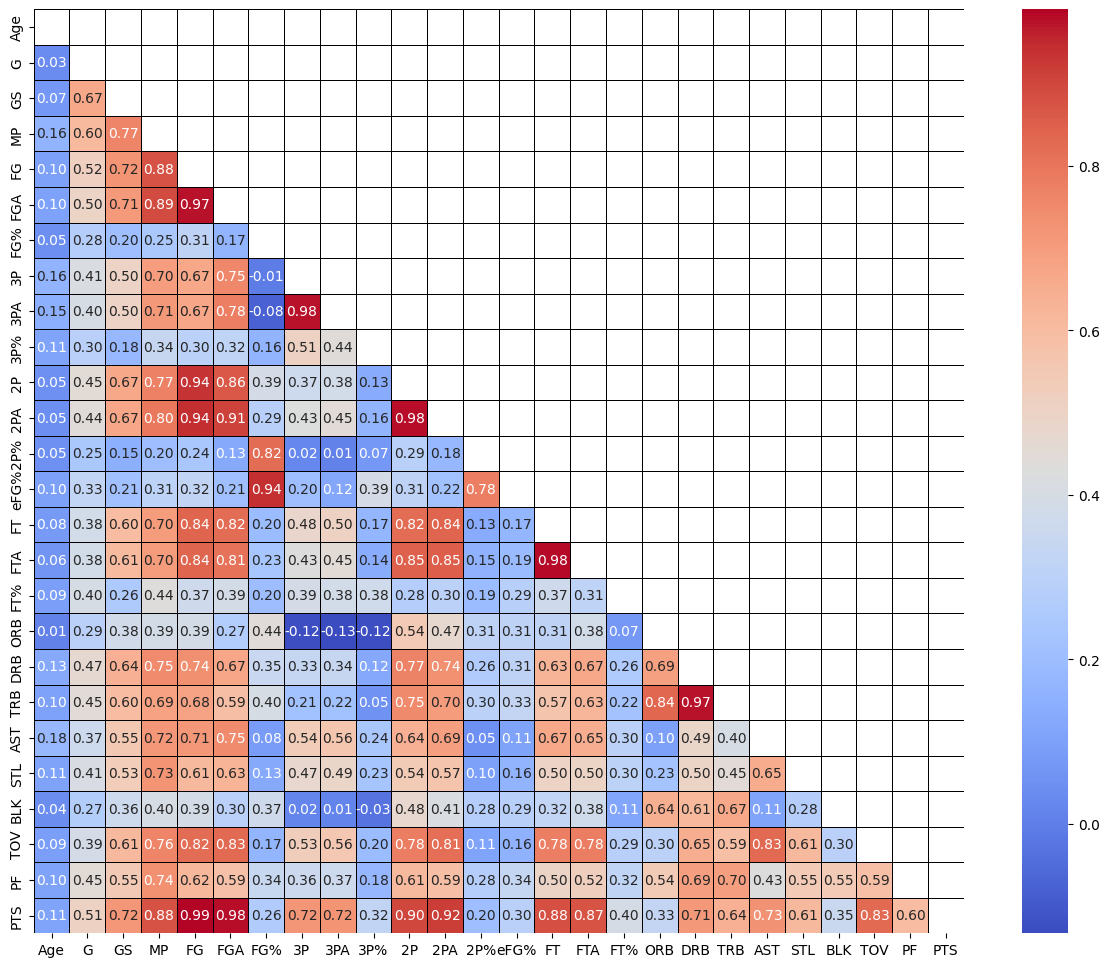

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

western_teams = ['OKC', 'DEN', 'LAL', 'HOU', 'SAS', 'PHO', 'MIN', 'GSW', 'POR', 'MEM', 'UTA', 'LAC', 'SAC', 'DAL', 'NOP']
guard = ['SG', 'PG']
feature_cols = ['Age', 'G', 'GS', 'MP', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS']

all_star_list_2024 = ['Giannis Antetokounmpo', 'Bam Adebayo', 'Tyrese Haliburton', 'Damian Lillard', 'Jayson Tatum', 'Paolo Banchero',
                 'Jaylen Brown', 'Jalen Brunson', 'Tyrese Maxey', 'Donovan Mitchell', 'Julius Randle', 'Joel Embiid',
                 'LeBron James', 'Luka Dončić', 'Kevin Durant', 'Shai Gilgeous-Alexander', 'Nikola Jokić', 'Devin Booker', 'Stephen Curry', 'Anthony Davis',
                 'Anthony Edwards', 'Paul George', 'Kawhi Leonard', 'Karl-Anthony Towns']
all_star_list_2023 = ['Giannis Antetokounmpo', 'Lauri Markkanen', 'Donovan Mitchell', 'Ja Morant', 'Jayson Tatum', 'Bam Adebayo',
                 'Shai Gilgeous-Alexander', 'DeMar DeRozan', 'Jrue Holiday', 'Damian Lillard', 'Domantas Sabonis', 'Kevin Durant',
                 'LeBron James', 'Luka Dončić', 'Joel Embiid', 'Kyrie Irving', 'Nikola Jokić', 'Jaylen Brown', 'Stephen Curry', 'Paul George',
                 'Tyrese Haliburton', 'Jaren Jackson Jr.', 'Julius Randle', 'Zion Williamson']
all_star_list_2022 = ['Kevin Durant', 'Joel Embiid', 'Ja Morant', 'Jayson Tatum', 'Andrew Wiggins', 'Trae Young',
                 'Devin Booker', 'Rudy Gobert', 'Zach LaVine', 'Khris Middleton', 'Karl-Anthony Towns', 'Draymond Green',
                 'LeBron James', 'Luka Dončić', 'Giannis Antetokounmpo', 'Stephen Curry', 'Nikola Jokić', 'DeMar DeRozan', 'Jimmy Butler', 'Darius Garland',
                 'James Harden', 'Donovan Mitchell', 'Chris Paul', 'Fred VanVleet']
all_star_list_2021 = ['Giannis Antetokounmpo', 'Stephen Curry', 'Luka Dončić', 'LeBron James', 'Nikola Jokić', 'Jaylen Brown',
                 'Paul George', 'Rudy Gobert', 'Damian Lillard', 'Chris Paul', 'Ben Simmons',
                 'Bradley Beal', 'Kyrie Irving', 'Kawhi Leonard', 'Jayson Tatum', 'Zion Williamson', 'James Harden', 'Zach LaVine', 'Donovan Mitchell',
                 'Julius Randle', 'Nikola Vučević', 'Devin Booker', 'Anthony Davis', 'Joel Embiid']
all_star_list_2020 = ['Anthony Davis', 'Kawhi Leonard', 'Luka Dončić', 'Damian Lillard', 'James Harden', 'Ben Simmons',
                 'Nikola Jokić', 'Jayson Tatum', 'Chris Paul', 'Russell Westbrook', 'Domantas Sabonis', 'LeBron James',
                 'Giannis Antetokounmpo', 'Joel Embiid', 'Pascal Siakam', 'Kemba Walker', 'Trae Young', 'Khris Middleton', 'Bam Adebayo', 'Rudy Gobert',
                 'Jimmy Butler', 'Kyle Lowry', 'Brandon Ingram', 'Donovan Mitchell']

def add_all_star_and_year(df, year, all_star_list):
  df['All Star'] = df['Player'].isin(all_star_list).astype(int)
  df['Year'] = year
  return df

df_2024 = add_all_star_and_year(clean_data(pd.read_csv("2023-2024.csv")), 2024, all_star_list_2024)
df_2023 = add_all_star_and_year(clean_data(pd.read_csv("2022-2023.csv")), 2023, all_star_list_2023)
df_2022 = add_all_star_and_year(clean_data(pd.read_csv("2021-2022.csv")), 2022, all_star_list_2022)
df_2021 = add_all_star_and_year(clean_data(pd.read_csv("2020-2021.csv")), 2021, all_star_list_2021)
df_2020 = add_all_star_and_year(clean_data(pd.read_csv("2019-2020.csv")), 2020, all_star_list_2020)

df_combined = pd.concat([df_2023, df_2022, df_2021, df_2020])

df_features = df_combined[feature_cols]

correlation_matrix = df_features.corr()
plt.figure(figsize=(15, 12))

mask = np.triu(correlation_matrix)
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    cbar=True,
    mask=mask,
    linewidths=.5,
    linecolor='black'
)

plt.show()
